In [16]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__,
      sklearn.__version__, matplotlib.__version__)

3.12.9 2.3.4 2.3.3 1.7.2 3.10.7


In [17]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 2586
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


**SEED = 2586** 

In [18]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]

## Part 1 - Bagging and out-of-bag estimates

In [19]:
def oob_mask(sample_indices, n_samples):
    """Return a boolean mask for rows absent from the bootstrap sample."""
    mask = np.ones(n_samples, dtype=bool)
    mask[np.asarray(sample_indices, dtype=np.intp)] = False
    return mask

In [20]:
np.testing.assert_array_equal(oob_mask([0, 2, 2], 5), [False, True, False, True, True])
np.testing.assert_array_equal(oob_mask([], 3), [True, True, True])
np.testing.assert_array_equal(oob_mask(np.array([3, 0]), 4), [False, True, True, False])

bag.fit(X_train, y_train)
n_train = len(y_train)
votes = np.zeros((n_train, 2), dtype=int)
oob_shares = []

for estimator, sample_indices in zip(bag.estimators_, bag.estimators_samples_):
    rows = np.flatnonzero(oob_mask(sample_indices, n_train))
    oob_shares.append(len(rows) / n_train)
    if rows.size:
        predicted = estimator.predict(X_train[rows]).astype(int)
        votes[rows, predicted] += 1

observed_oob = np.mean(oob_shares)
expected_oob = (1 - 1 / n_train) ** n_train
manual_oob = np.mean(votes.argmax(axis=1) == y_train)

print(f"OOB share: observed {observed_oob:.6f}, theory {expected_oob:.6f}")
print(f"In-bag share: observed {1 - observed_oob:.6f}, theory {1 - expected_oob:.6f}")
print(f"OOB accuracy: manual {manual_oob:.6f}, sklearn {bag.oob_score_:.6f}")
assert manual_oob == bag.oob_score_

OOB share: observed 0.367253, theory 0.367821
In-bag share: observed 0.632747, theory 0.632179
OOB accuracy: manual 0.935934, sklearn 0.935934


In [21]:
from sklearn.model_selection import cross_validate


def cv_accuracy(model):
    return cross_validate(
        model, X_train, y_train, cv=cv, scoring="accuracy"
    )["test_score"]


def fold_table(scores):
    table = pd.DataFrame.from_dict(scores, orient="index")
    table.columns = [f"Fold {i}" for i in range(1, cv.n_splits + 1)]
    table["Mean"] = table.mean(axis=1)
    table["Std"] = np.array([np.std(values) for values in scores.values()])
    return table


cv_scores = {
    name: cv_accuracy(model)
    for name, model in {"tree": tree, "bag": bag, "rf": rf, "lr": lr, "bag_lr": bag_lr}.items()
}

part1_scores = {
    **cv_scores,
    "bag − tree": cv_scores["bag"] - cv_scores["tree"],
    "rf − tree": cv_scores["rf"] - cv_scores["tree"],
    "bag_lr − lr": cv_scores["bag_lr"] - cv_scores["lr"],
}

print(fold_table(part1_scores).to_string(float_format="{:.6f}".format))

               Fold 1   Fold 2    Fold 3   Fold 4   Fold 5     Mean      Std
tree         0.912837 0.903328  0.890650 0.884127 0.914286 0.901045 0.011949
bag          0.931854 0.936609  0.939778 0.942857 0.942857 0.938791 0.004170
rf           0.936609 0.952456  0.947702 0.952381 0.942857 0.946401 0.006043
lr           0.930269 0.936609  0.947702 0.936508 0.947619 0.939741 0.006862
bag_lr       0.928685 0.942948  0.946117 0.938095 0.950794 0.941328 0.007556
bag − tree   0.019017 0.033281  0.049128 0.058730 0.028571 0.037746 0.014316
rf − tree    0.023772 0.049128  0.057052 0.068254 0.028571 0.045356 0.016870
bag_lr − lr -0.001585 0.006339 -0.001585 0.001587 0.003175 0.001586 0.003007


In [22]:
rf.fit(X_train, y_train)
rf_cv_mean = cv_scores["rf"].mean()
rf_cv_std = cv_scores["rf"].std()
rf_test_accuracy = rf.score(X_test, y_test)
rf_test_se = np.sqrt(rf_test_accuracy * (1 - rf_test_accuracy) / len(y_test))

print(f"Forest OOB accuracy: {rf.oob_score_:.6f}")
print(f"Forest CV accuracy: {rf_cv_mean:.6f} ± {rf_cv_std:.6f}")
print(f"Forest test accuracy: {rf_test_accuracy:.6f}, SE: {rf_test_se:.6f}")
print(f"|OOB − CV|: {abs(rf.oob_score_ - rf_cv_mean):.6f}")
print(f"|OOB − test|: {abs(rf.oob_score_ - rf_test_accuracy):.6f}")
print(f"|CV − test|: {abs(rf_cv_mean - rf_test_accuracy):.6f}")

Forest OOB accuracy: 0.947352
Forest CV accuracy: 0.946401 ± 0.006043
Forest test accuracy: 0.949572, SE: 0.006750
|OOB − CV|: 0.000951
|OOB − test|: 0.002220
|CV − test|: 0.003171


### Results and interpretation

**Out-of-bag check.** The observed OOB share was 0.367253, close to the theoretical value of 0.367821. The observed in-bag share was 0.632747, compared with the theoretical value of 0.632179. The manual OOB accuracy matched `bag.oob_score_` at 0.935934.

**Decision tree.** Bagging improved accuracy on all five folds. The mean paired gain was 0.037746, larger than the paired standard deviation of 0.014316. A deep tree is sensitive to changes in its training sample. Combining trees trained on different bootstrap samples can reduce this variability.

**Logistic regression.** The mean paired gain was 0.001586, within the paired standard deviation of 0.003007. The folds do not show a clear improvement. Logistic regression is typically more stable across bootstrap samples, so bagging has less variability to reduce.

**Random forest.** OOB accuracy was 0.947352 and mean CV accuracy was 0.946401. Their gap of 0.000951 was smaller than the CV standard deviation of 0.006043, so OOB was a reasonable substitute for CV on this split. Test accuracy was 0.949572 with a standard error of 0.006750. OOB and CV were below test accuracy by 0.002220 and 0.003171, respectively. Both gaps were smaller than one test standard error.

## Part 2 - Evaluating the spam filter

In [23]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_curve
from sklearn.model_selection import cross_val_predict

oof_rf = cross_val_predict(
    rf, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

oof_fpr, oof_recall, thresholds = roc_curve(
    y_train, oof_rf, drop_intermediate=False
)

eligible = oof_fpr <= 0.01
best_recall = oof_recall[eligible].max()
t = thresholds[eligible & (oof_recall == best_recall)].max()
threshold_index = np.flatnonzero(thresholds == t)[0]

print(f"Selected threshold: {t:.16g}")
print(f"OOF FPR: {oof_fpr[threshold_index]:.4%}")
print(f"OOF recall: {oof_recall[threshold_index]:.4%}")

rf_test_scores = rf.predict_proba(X_test)[:, 1]
test_flags = (rf_test_scores >= t).astype(int)

cm = confusion_matrix(y_test, test_flags, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("\nTest confusion matrix")
print(pd.DataFrame(
    cm,
    index=["Actual legitimate", "Actual spam"],
    columns=["Predicted legitimate", "Predicted spam"],
).to_string())

print(f"\nTest precision: {precision_score(y_test, test_flags, zero_division=0):.4%}")
print(f"Test recall: {recall_score(y_test, test_flags):.4%}")
print(f"Test FPR: {fp / (tn + fp):.4%}")
print(f"{fp} of {tn + fp} legitimate test emails were flagged as spam.")

Selected threshold: 0.7366666666666667
OOF FPR: 0.9494%
OOF recall: 82.1798%

Test confusion matrix
                   Predicted legitimate  Predicted spam
Actual legitimate                   624               8
Actual spam                          68             351

Test precision: 97.7716%
Test recall: 83.7709%
Test FPR: 1.2658%
8 of 632 legitimate test emails were flagged as spam.


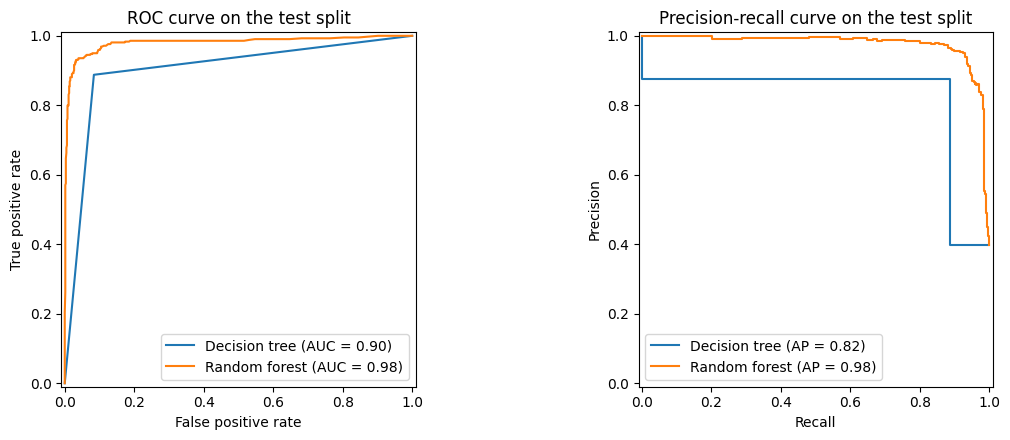

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

tree.fit(X_train, y_train)
tree_test_scores = tree.predict_proba(X_test)[:, 1]

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 4.5))

for name, scores in [
    ("Decision tree", tree_test_scores),
    ("Random forest", rf_test_scores),
]:
    RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=ax_roc)
    PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=ax_pr)

ax_roc.set(title="ROC curve on the test split", xlabel="False positive rate",
           ylabel="True positive rate")
ax_pr.set(title="Precision-recall curve on the test split", xlabel="Recall",
          ylabel="Precision")

fig.tight_layout()
plt.show()

In [25]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf, X_test, y_test, n_repeats=10, random_state=SEED, scoring="accuracy"
)

mdi = pd.Series(rf.feature_importances_, index=feature_names, name="MDI")
perm_accuracy = pd.Series(
    perm.importances_mean, index=feature_names, name="Mean accuracy drop"
)

print("Top 5 impurity importances")
print(mdi.nlargest(5).to_frame().to_string(float_format="{:.6f}".format))

print("\nTop 5 permutation importances")
print(perm_accuracy.nlargest(5).to_frame().to_string(float_format="{:.6f}".format))

feature = "capital_run_length_average"
related_features = ["capital_run_length_longest", "capital_run_length_total"]

print(f"\nMDI rank: {mdi.rank(ascending=False).loc[feature]:g}")
print(f"Permutation rank: {perm_accuracy.rank(ascending=False).loc[feature]:g}")
print(f"Mean test accuracy drop: {perm_accuracy.loc[feature]:.6f}")

train_features = pd.DataFrame(X_train, columns=feature_names)
correlations = train_features[related_features].corrwith(train_features[feature])
print("\nTraining correlations with capital_run_length_average")
print(correlations.round(3).to_string())

Top 5 impurity importances
                                MDI
char_freq_exclam           0.113624
char_freq_dollar           0.089327
word_freq_remove           0.083094
capital_run_length_average 0.066300
word_freq_free             0.065143

Top 5 permutation importances
                  Mean accuracy drop
word_freq_remove            0.030447
char_freq_exclam            0.015128
word_freq_hp                0.014462
char_freq_dollar            0.009039
word_freq_george            0.006089

MDI rank: 4
Permutation rank: 9.5
Mean test accuracy drop: 0.003235

Training correlations with capital_run_length_average
capital_run_length_longest    0.470
capital_run_length_total      0.165


### Results and interpretation

**Threshold.** The selected threshold was approximately 0.736667. On the training folds, it gave an out-of-fold false positive rate of 0.9494% and a recall of 82.18%. On the test split, precision was 97.77% and recall was 83.77%. The filter flagged 8 of 632 legitimate emails, giving a false positive rate of 1.27%. The 1% target was exceeded on the test split.

**Feature importance.** `capital_run_length_average` ranked fourth by impurity importance and tied for ninth by permutation importance. The feature contributed to impurity reduction in training splits, but shuffling it reduced test accuracy by only 0.32 percentage points on average. Its training correlation with `capital_run_length_longest` was 0.470. Because the longest run stays unchanged when the average is shuffled, it may preserve some of the same information in trees that use it. This could help explain why the average ranks higher by impurity reduction than by its effect on test accuracy.